In [ ]:
import numpy as np
import matplotlib.pyplot as plt

GRAVITY = 9.81 
MOUTH_HEIGHT = 0.55
FRAME_TIME = 1 / 60

In [ ]:
def rates(state):
    vx, vy, vz, k = state[3:7]
    speed = np.sqrt(vx**2 + vy**2 + vz**2)

    acceleration_x =          - k * speed * vx
    acceleration_y =          - k * speed * vy
    acceleration_z = -GRAVITY - k * speed * vz

    return np.array([vx, vy, vz,
                     acceleration_x, acceleration_y, acceleration_z,
                     0.0])

position_frame0 = np.array([-5.000, 0.300, 2.000]) 
position_frame5 = np.array([-2.903, 0.349, 3.731])
frames_apart = 5

velocity = (position_frame5 - position_frame0) / (frames_apart * FRAME_TIME)
print("velocity estimate (m/s):", np.round(velocity, 2))
print("speed (m/s):", round(np.linalg.norm(velocity), 1))

state = np.array([*position_frame5, *velocity, 0.22])
print("rates:", np.round(rates(state), 1))

velocity estimate (m/s): [25.16  0.59 20.77]
speed (m/s): 32.6
rates: [  25.2    0.6   20.8 -180.7   -4.2 -158.9    0. ]


In [14]:
def step_euler(state, frame_time):
    return state + frame_time * rates(state)


def step_rk4(state, frame_time):
    slope1 = rates(state)
    slope2 = rates(state + 0.5 * frame_time * slope1)
    slope3 = rates(state + 0.5 * frame_time * slope2)
    slope4 = rates(state +       frame_time * slope3)
    return state + (frame_time / 6) * (slope1 + 2*slope2 + 2*slope3 + slope4)


one_euler = step_euler(state, FRAME_TIME)
one_rk4   = step_rk4(state, FRAME_TIME)
print("current state:         ", np.round(state, 3))
print("after one frame, Euler:", np.round(one_euler, 3))
print("after one frame, RK4:  ", np.round(one_rk4, 3))
print("position difference (cm):", np.round(100 * (one_euler[:3] - one_rk4[:3]), 2))

current state:          [-2.903  0.349  3.731 25.164  0.588 20.772  0.22 ]
after one frame, Euler: [-2.484  0.359  4.077 22.153  0.518 18.123  0.22 ]
after one frame, RK4:   [-2.507  0.358  4.057 22.479  0.525 18.401  0.22 ]
position difference (cm): [2.32 0.05 2.05]


In [ ]:
def fly(start_state, frame_time=FRAME_TIME, stepper=step_rk4, max_time=4.0):
    states = [start_state.copy()]
    times = [0.0]
    state = start_state.copy()
    while times[-1] < max_time:
        new_state = stepper(state, frame_time)
        # crossed mouth height on the way down?
        if new_state[2] <= MOUTH_HEIGHT and new_state[5] < 0 and state[2] > MOUTH_HEIGHT:
            fraction = (state[2] - MOUTH_HEIGHT) / (state[2] - new_state[2])
            landing = state + fraction * (new_state - state)
            states.append(landing)
            times.append(times[-1] + fraction * frame_time)
            break
        state = new_state
        states.append(state.copy())
        times.append(times[-1] + frame_time)
    return np.array(times), np.array(states)


def start_from_launch(position, launch_speed, launch_angle_deg, side_angle_deg=0.0, k=0.22):
    up = np.radians(launch_angle_deg)
    side = np.radians(side_angle_deg)
    vx = launch_speed * np.cos(up) * np.cos(side)
    vy = launch_speed * np.cos(up) * np.sin(side)
    vz = launch_speed * np.sin(up)
    return np.array([*position, vx, vy, vz, k])


times, states = fly(start_from_launch(position=(-5.0, 0.0, 2.0), launch_speed=45, launch_angle_deg=40))
land = states[-1]
print(f"flight time: {times[-1]:.2f} s")
print(f"lands at mouth height at px = {land[0]:.2f} m, py = {land[1]:.2f} m")
print(f"speed at landing: {np.linalg.norm(land[3:6]):.1f} m/s")

flight time: 2.13 s
lands at mouth height at px = 5.97 m, py = 0.00 m
speed at landing: 6.4 m/s


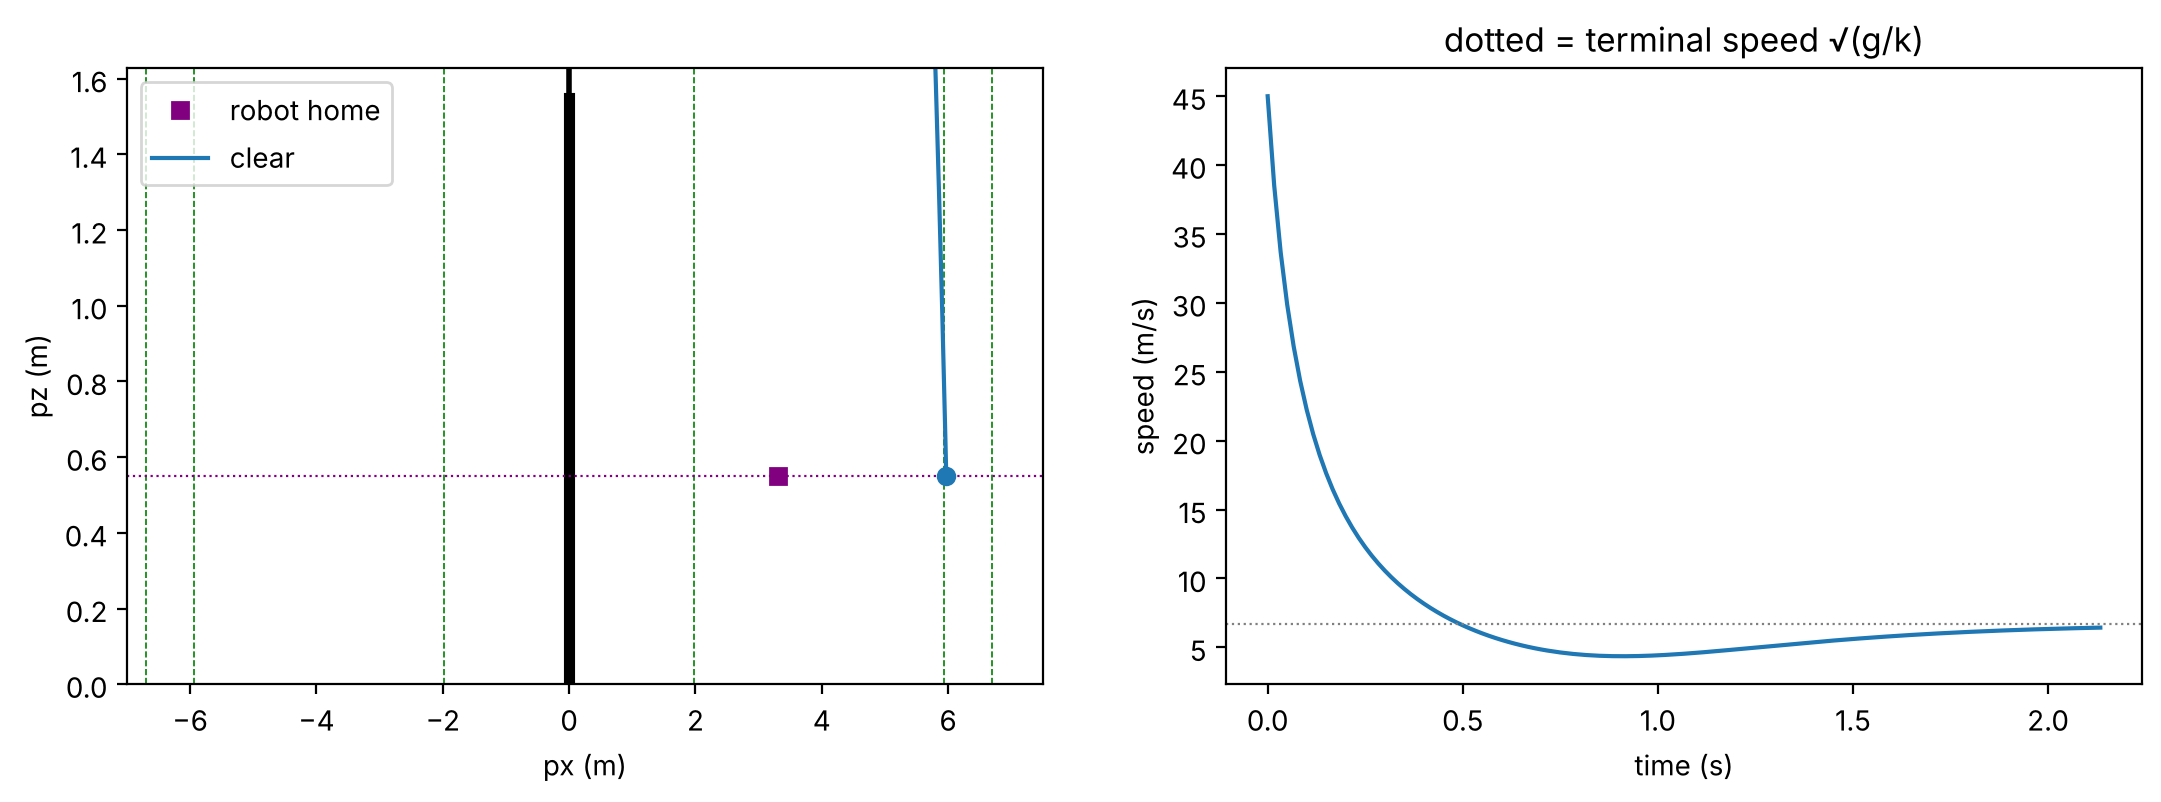

In [5]:
def draw_court(ax):
    ax.axvline(0, color="k", lw=2)
    ax.plot([0, 0], [0, 1.55], color="k", lw=4)                 # net
    for line in (1.98, 5.94, 6.70):
        ax.axvline(line, color="green", lw=0.6, ls="--")
        ax.axvline(-line, color="green", lw=0.6, ls="--")
    ax.axhline(MOUTH_HEIGHT, color="purple", lw=0.8, ls=":")
    ax.plot(3.3, MOUTH_HEIGHT, "s", color="purple", label="robot home")
    ax.set_xlim(-7, 7.5); ax.set_ylim(0, None)
    ax.set_xlabel("px (m)"); ax.set_ylabel("pz (m)")


def plot_shot(times, states, label=None, axes=None):
    if axes is None:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        draw_court(axes[0])
    axes[0].plot(states[:, 0], states[:, 2], label=label)
    axes[0].plot(states[-1, 0], states[-1, 2], "o", color=axes[0].lines[-1].get_color())
    axes[1].plot(times, np.linalg.norm(states[:, 3:6], axis=1), label=label)
    axes[1].axhline(np.sqrt(GRAVITY / states[0, 6]), color="gray", ls=":", lw=0.8)
    axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("speed (m/s)")
    axes[1].set_title("dotted = terminal speed √(g/k)")
    return axes


axes = plot_shot(times, states, label="clear")
axes[0].legend(); plt.show()

## 5. How much does k matter?

Same hit, different k. This is why the filter estimates k live: a small error moves the landing a lot.

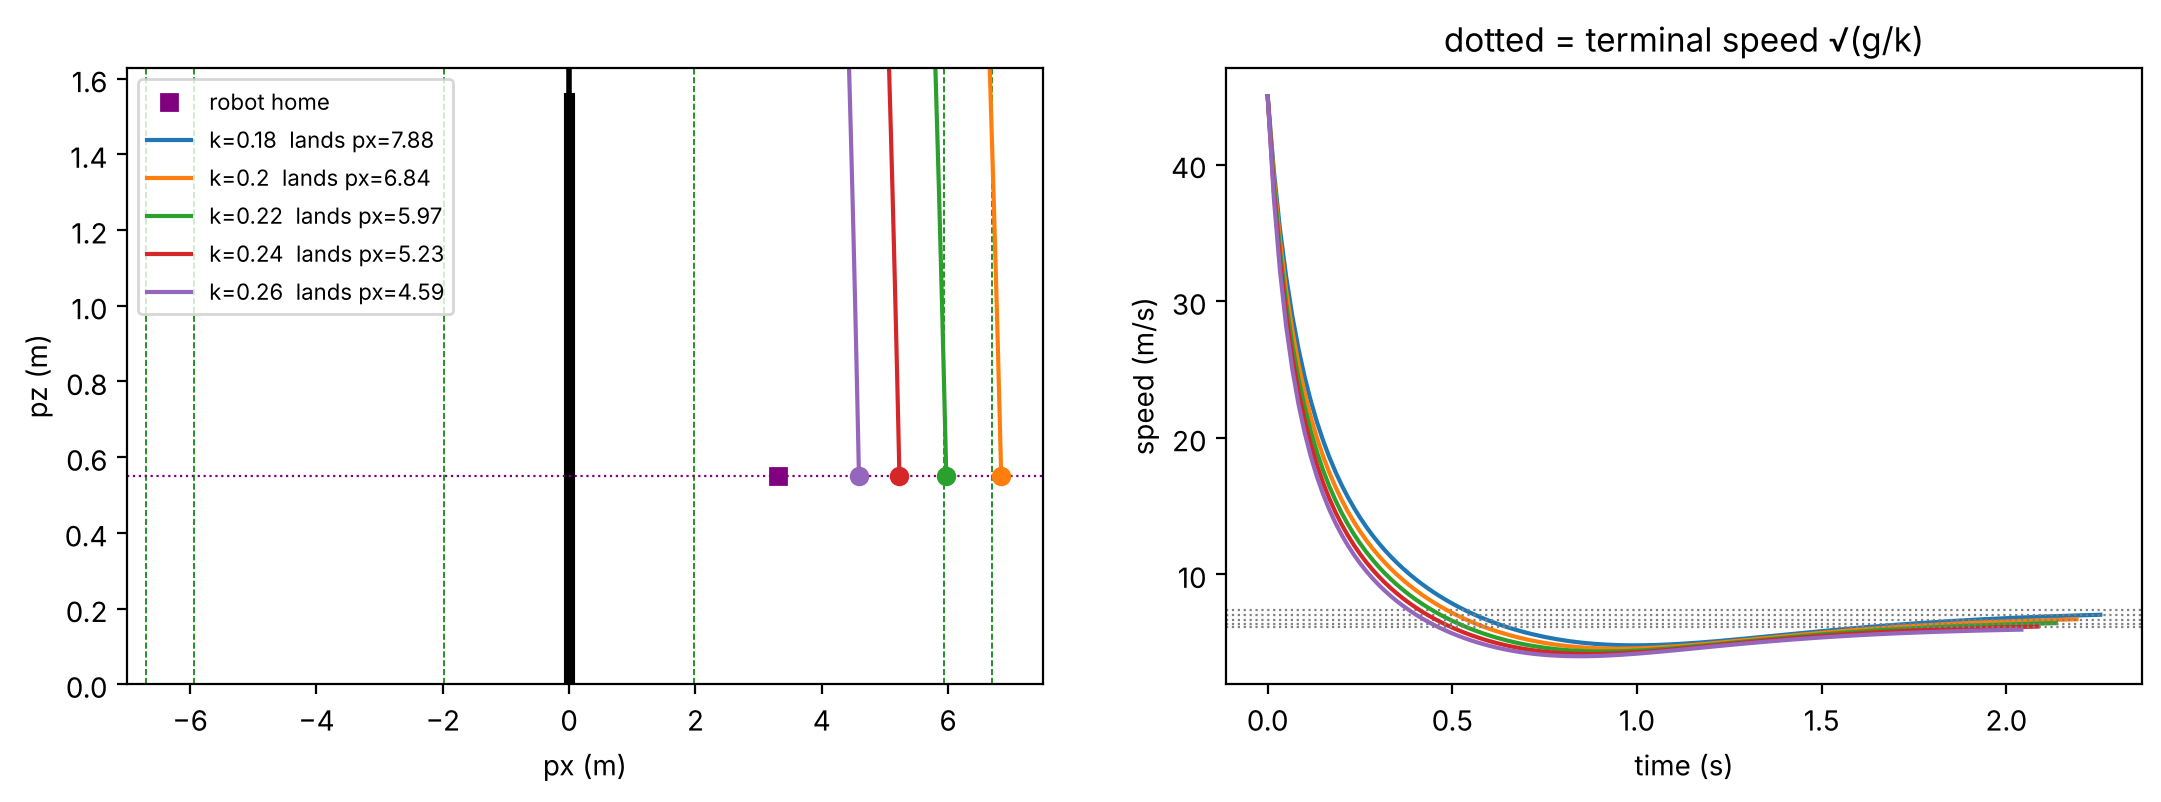

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
draw_court(axes[0])
for k in (0.18, 0.20, 0.22, 0.24, 0.26):
    t, s = fly(start_from_launch((-5.0, 0.0, 2.0), 45, 40, k=k))
    plot_shot(t, s, label=f"k={k}  lands px={s[-1,0]:.2f}", axes=axes)
axes[0].legend(fontsize=8); plt.show()